<a href="https://colab.research.google.com/github/hkaido0718/SupportRestriction/blob/atsuki-update_functions_documents/PartialMonotonicityModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The `PartialMonotonicityModel` class: a vector instrument with partial monotonicity
Let $Y$ denote an outcome and $D$ a treatment, each with a finite support, and let $Z=(Z_1,\dots,Z_m)$ be an instrument vector whose support is the Cartesian product of finite coordinate supports. For example, with $m=2$, $D$ is college attendance, $Z_1$ indicates a low opportunity cost of attendance and $Z_2$ the presence of a nearby college, as in the repository's `Partial_Monotonicity.ipynb`. Let $D(z)$ and $Y(d,z)$ denote the potential treatment and the potential outcome, with observed responses $D=D(Z)$ and $Y=Y(D(Z),Z)$, where the full vector $\big((Y(d,z))_{d,z},(D(z))_z\big)$ is independent of $Z$.

The `PartialMonotonicityModel` class in `partial_monotonicity_model.py` always imposes the partial monotonicity assumption of Mogstad, Torgovitsky and Walters (2021): $D(z)$ is nondecreasing in each coordinate of $z$, holding the other coordinates fixed. On a product support this is the same as

\begin{align}
D(z)\leqslant_{a.s.} D(z') \quad\text{whenever } z_j\leqslant z'_j \text{ for every coordinate } j .
\end{align}

Instrument vectors that are incomparable in this componentwise order, such as $(0,1)$ and $(1,0)$, impose no ordering on the treatment. Exclusion, $Y(d,z)=Y(d,z')$ for all $d,z,z'$, is optional and on by default. No outcome monotonicity is imposed.

Each model is represented by a graph $G$ whose nodes are the observable events $(y,d,z)$, with $z$ a tuple. `build_graph()` constructs $G$ by Method 1 of Kaido and Ponomarev (2025): a pair of nodes with different instrument vectors is joined unless partial monotonicity rejects it (comparable vectors with the treatment larger at the smaller vector) or, when enabled, exclusion rejects it (equal treatment, unequal outcome). The graph is then analyzed with `GraphAnalyzer`, exactly as in the other notebooks.

In [1]:
# Inside a local checkout, the modules are importable from the working directory.
# Anywhere else (for example Google Colab), fetch the repository, check out the
# branch or commit under review, and add it to the path.
import os
import sys

REPO_URL = "https://github.com/hkaido0718/SupportRestriction.git"
REPO_REF = "atsuki-update_functions_documents"  # branch, tag or commit to load; use "main" once merged

if not os.path.isfile("partial_monotonicity_model.py"):
    if not os.path.isdir("SupportRestriction"):
        !git clone --quiet {REPO_URL}
    !git -C SupportRestriction checkout --quiet {REPO_REF}
    sys.path.insert(0, os.path.abspath("SupportRestriction"))

In [2]:
# Confirm which checkout the modules are imported from.
import subprocess

import partial_monotonicity_model
import iv_model
import graph_analysis_utils

for module in (partial_monotonicity_model, iv_model, graph_analysis_utils):
    print(f"{module.__name__:27s} imported from {os.path.relpath(module.__file__)}")

repo_dir = os.path.dirname(os.path.abspath(partial_monotonicity_model.__file__))

def git(*args):
    result = subprocess.run(["git", "-C", repo_dir, *args], capture_output=True, text=True)
    return result.stdout.strip() or "?"

print(f"checkout: {git('rev-parse', '--abbrev-ref', 'HEAD')} at commit {git('rev-parse', '--short', 'HEAD')}")

partial_monotonicity_model  imported from partial_monotonicity_model.py
iv_model                    imported from iv_model.py
graph_analysis_utils        imported from graph_analysis_utils.py
checkout: atsuki-update_functions_documents at commit f7e3c4d


## 1. Binary outcome, binary treatment, two binary instruments
With $Y,D\in\{0,1\}$ and $Z\in\{0,1\}^2$ there are 16 nodes in four instrument groups, hence $6\times 16=96$ cross-group pairs. Five of the six pairs of instrument vectors are comparable; $(0,1)$ and $(1,0)$ are not. Partial monotonicity removes, on each comparable pair, the four events with $D=1$ at the smaller vector and $D=0$ at the larger one (20 pairs); exclusion removes, on every pair of vectors, the four events with equal treatment and unequal outcome (24 pairs). The two sets are disjoint, so the graph has 76 edges without exclusion and 52 with it.

In [3]:
from itertools import combinations

from partial_monotonicity_model import PartialMonotonicityModel
from iv_model import IVModel
from graph_analysis_utils import GraphAnalyzer

binary = dict(y_support=(0, 1), d_support=(0, 1), z_supports=((0, 1), (0, 1)))
models = {
    "Partial monotonicity only": PartialMonotonicityModel(**binary, exclusion=False),
    "Partial monotonicity and exclusion": PartialMonotonicityModel(**binary, exclusion=True),
}
graphs = {name: model.build_graph() for name, model in models.items()}

for name, G in graphs.items():
    print(f"{name:36s} nodes = {G.number_of_nodes()}, edges = {G.number_of_edges()}")
print()
print(models["Partial monotonicity and exclusion"].summary())

Partial monotonicity only            nodes = 16, edges = 76
Partial monotonicity and exclusion   nodes = 16, edges = 52

PartialMonotonicityModel: discrete IV model with a vector instrument (Kaido and Ponomarev, 2025)
  Outcome support Y:    (0, 1)
  Treatment support D:  (0, 1)
  Instrument coordinates: 2, Z = (Z1, Z2)
    Z1: (0, 1)
    Z2: (0, 1)
  Instrument support Z: Cartesian product, 4 vectors
  Nodes (y, d, z):      16
  Potential responses: D(z) and Y(d, z); observed D = D(Z), Y = Y(D(Z), Z).
  Assumptions:
    - Partial monotonicity: imposed (always). D(z) is nondecreasing in each
      instrument coordinate holding the others fixed, so D(z) <= D(z')
      whenever z <= z' componentwise; incomparable instrument vectors impose
      no ordering on D.
    - Exclusion: imposed. Y(d, z) = Y(d, z') for every treatment value d and every pair of instrument vectors z, z'.
    - No outcome monotonicity is imposed.
  Maintained (not a pairwise rule): the full potential-response vector

### Selected pairs
The pairs below are the ones listed in the specification. The first is rejected by partial monotonicity under either setting, the second and third are edges under either setting (the third because $(1,0)$ and $(0,1)$ are incomparable), and the fourth is an edge only without exclusion: incomparability does not override exclusion. Each pair is checked in both argument orders.

In [4]:
pairs = [
    ((0, 1, (0, 0)), (0, 0, (1, 1)), "(0,0) <= (1,1) but D falls: rejected by partial monotonicity"),
    ((1, 0, (0, 0)), (0, 1, (1, 1)), "(0,0) <= (1,1) and D rises: compatible"),
    ((1, 1, (1, 0)), (0, 0, (0, 1)), "(1,0), (0,1) incomparable, treatments differ: compatible"),
    ((0, 0, (1, 0)), (1, 0, (0, 1)), "(1,0), (0,1) incomparable, equal D, unequal Y: exclusion decides"),
]
for u, v, reason in pairs:
    row = "  ".join(
        f"{'edge' if G.has_edge(u, v) and G.has_edge(v, u) else 'no edge':7s} ({name.split()[0]}{' + excl' if 'exclusion' in name else ''})"
        for name, G in graphs.items()
    )
    print(f"{u} -- {v}: {row}\n    {reason}")

(0, 1, (0, 0)) -- (0, 0, (1, 1)): no edge (Partial)  no edge (Partial + excl)
    (0,0) <= (1,1) but D falls: rejected by partial monotonicity
(1, 0, (0, 0)) -- (0, 1, (1, 1)): edge    (Partial)  edge    (Partial + excl)
    (0,0) <= (1,1) and D rises: compatible
(1, 1, (1, 0)) -- (0, 0, (0, 1)): edge    (Partial)  edge    (Partial + excl)
    (1,0), (0,1) incomparable, treatments differ: compatible
(0, 0, (1, 0)) -- (1, 0, (0, 1)): edge    (Partial)  no edge (Partial + excl)
    (1,0), (0,1) incomparable, equal D, unequal Y: exclusion decides


### Plots

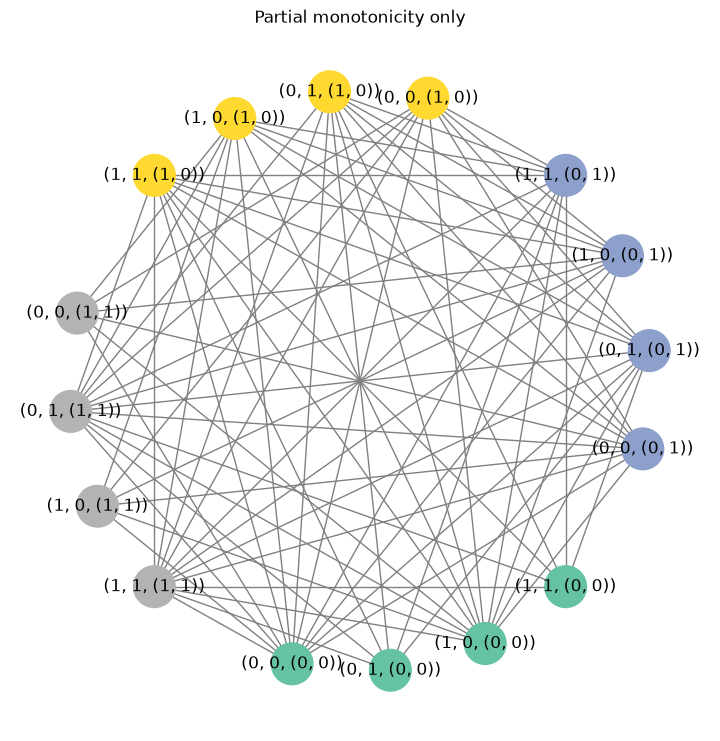

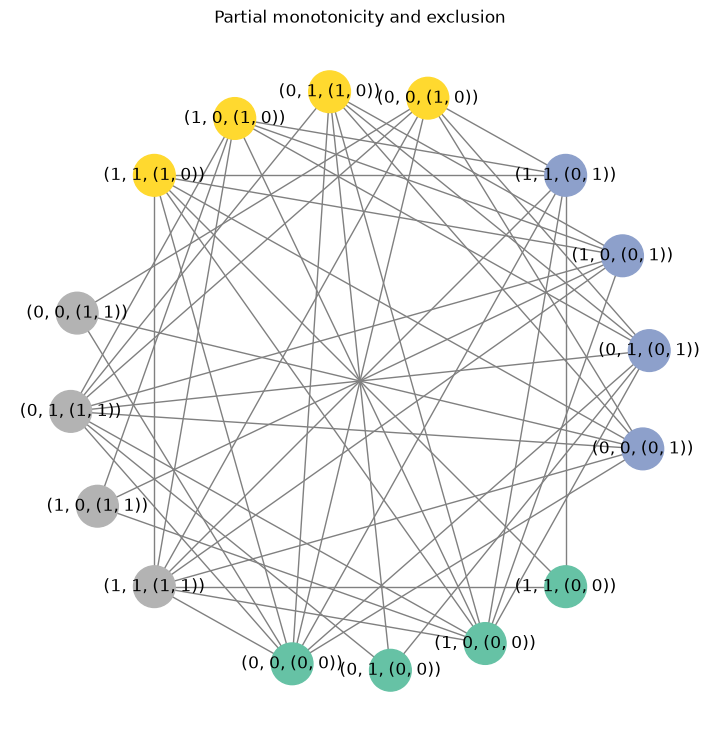

In [5]:
for name, G in graphs.items():
    analyzer = GraphAnalyzer(G, group_fn=models[name].group_fn)
    analyzer.plot_grouped_on_circle(title=name, node_size=900, figsize=(7, 7))

### Maximal independent sets and the testable implications
Each maximal independent set (MIS) that spans more than one instrument group gives an inequality: the conditional probabilities of its events, one group at a time, sum to at most one. The model's `format_inequalities` writes each set as that inequality, spelling the instrument vector coordinate by coordinate and merging the two outcomes of a treatment into $P(D=d\mid Z=z)$ when both appear.

In [6]:
for name, G in graphs.items():
    analyzer = GraphAnalyzer(G, group_fn=models[name].group_fn)
    mis_list = analyzer.find_mis_excluding_single_group()
    inequalities = models[name].format_inequalities(mis_list)
    print(f"{name}: {len(mis_list)} MISs excluding single-group ones")
    if len(inequalities) > 12:
        print("    (first six)")
        inequalities = inequalities[:6]
    for inequality in inequalities:
        print("   ", inequality)
    print()


Partial monotonicity only: 5 MISs excluding single-group ones
    P(D=1 | Z1=0, Z2=0) + P(D=0 | Z1=1, Z2=0) <= 1
    P(D=1 | Z1=0, Z2=0) + P(D=0 | Z1=0, Z2=1) <= 1
    P(D=1 | Z1=0, Z2=0) + P(D=0 | Z1=1, Z2=1) <= 1
    P(D=1 | Z1=1, Z2=0) + P(D=0 | Z1=1, Z2=1) <= 1
    P(D=1 | Z1=0, Z2=1) + P(D=0 | Z1=1, Z2=1) <= 1

Partial monotonicity and exclusion: 45 MISs excluding single-group ones
    (first six)
    P(Y=1, D=1 | Z1=0, Z2=0) + P(D=0 | Z1=1, Z2=1) + P(Y=0, D=1 | Z1=1, Z2=1) <= 1
    P(D=1 | Z1=0, Z2=0) + P(D=0 | Z1=0, Z2=1) <= 1
    P(D=1 | Z1=0, Z2=0) + P(Y=0, D=0 | Z1=0, Z2=1) + P(Y=1, D=0 | Z1=1, Z2=1) <= 1
    P(Y=1, D=0 | Z1=0, Z2=0) + P(D=1 | Z1=0, Z2=0) + P(Y=0, D=0 | Z1=0, Z2=1) <= 1
    P(D=1 | Z1=0, Z2=0) + P(Y=0, D=0 | Z1=0, Z2=1) + P(Y=1, D=0 | Z1=1, Z2=0) <= 1
    P(D=1 | Z1=0, Z2=0) + P(Y=1, D=0 | Z1=0, Z2=1) + P(Y=0, D=0 | Z1=1, Z2=1) <= 1



Without exclusion the five inequalities are exactly those derived in `Partial_Monotonicity.ipynb` for the treatment alone: one for each comparable pair of instrument vectors, $P(D=1\mid Z=z)+P(D=0\mid Z=z')\leqslant 1$ for $z\leqslant z'$ componentwise. With exclusion the outcome enters and the number of MISs grows considerably.

### Regularity
Condition 2 of the paper (every maximal clique is a support point) holds for this class by construction: the module docstring gives the completion argument, and `enumerate_cliques_and_check` confirms it on the graph. Perfectness is checked numerically. Without exclusion the graph is perfect, so the five inequalities above are sharp. With exclusion the graph is not perfect, so the MIS inequalities are necessary but need not be sharp; this parallels the exclusion-only scalar model with three instrument values in `IVModel_Exclusion_Monotonicity.ipynb`.

In [7]:
for name, G in graphs.items():
    model = models[name]
    analyzer = GraphAnalyzer(G, group_fn=model.group_fn)
    rows = analyzer.enumerate_cliques_and_check(model.violate_pairwise_fn)
    print(f"{name}: perfect = {analyzer.is_perfect()}, "
          f"maximal cliques = {len(rows)}, all support points = {all(r['satisfies_condition'] for r in rows)}")

Partial monotonicity only: perfect = True, maximal cliques = 96, all support points = True
Partial monotonicity and exclusion: perfect = False, maximal cliques = 20, all support points = True


## 2. One instrument: agreement with `IVModel`
With a single coordinate the instrument vector is $z=(z_1,)$ and the componentwise order is the scalar order, so the model coincides with `IVModel` under nondecreasing D-monotonicity. The cell compares the edge sets after translating $(y,d,(z_1,))$ to $(y,d,z_1)$, with exclusion on and off, on three support sets.

In [8]:
def edge_set(G):
    return {frozenset(e) for e in G.edges()}

supports = [
    ((0, 1), (0, 1), (0, 1)),
    ((0, 1), (0, 2, 5), (-1, 3, 10)),
    ((0, 1, 2), (0, 2, 5), (-1, 3, 10)),
]
for y_support, d_support, z_support in supports:
    for exclusion in (True, False):
        vector = PartialMonotonicityModel(y_support, d_support, (z_support,), exclusion=exclusion)
        scalar = IVModel(y_support, d_support, z_support, exclusion=exclusion, d_monotonicity=True)
        projected = {frozenset((y, d, z[0]) for (y, d, z) in e) for e in edge_set(vector.build_graph())}
        agree = projected == edge_set(scalar.build_graph())
        print(f"Y={y_support}, D={d_support}, Z={z_support}, exclusion={exclusion!s:5s}: "
              f"{len(projected)} edges, agrees with IVModel: {agree}")

Y=(0, 1), D=(0, 1), Z=(0, 1), exclusion=True : 8 edges, agrees with IVModel: True
Y=(0, 1), D=(0, 1), Z=(0, 1), exclusion=False: 12 edges, agrees with IVModel: True
Y=(0, 1), D=(0, 2, 5), Z=(-1, 3, 10), exclusion=True : 54 edges, agrees with IVModel: True
Y=(0, 1), D=(0, 2, 5), Z=(-1, 3, 10), exclusion=False: 72 edges, agrees with IVModel: True
Y=(0, 1, 2), D=(0, 2, 5), Z=(-1, 3, 10), exclusion=True : 108 edges, agrees with IVModel: True
Y=(0, 1, 2), D=(0, 2, 5), Z=(-1, 3, 10), exclusion=False: 162 edges, agrees with IVModel: True


## 3. Small nonbinary supports
With $Y\in\{0,1,2\}$, $D\in\{0,2,5\}$ and $Z\in\{0,1,2\}\times\{10,20\}$ there are 54 nodes in six instrument groups. Three of the fifteen pairs of instrument vectors are incomparable: $(0,20)$ with $(1,10)$ and $(2,10)$, and $(1,20)$ with $(2,10)$. On each of the twelve comparable pairs, partial monotonicity removes the three falling treatment pairs times nine outcome combinations ($12\times 27=324$ of the $15\times 81=1215$ cross-group pairs); exclusion removes three equal treatments times six unequal outcome pairs on every vector pair ($15\times 18=270$). Hence 891 edges without exclusion and 621 with it. Note that $(0,20)<(1,10)$ in Python's lexicographic tuple order, which is never used by the class.

In [9]:
nonbinary = dict(y_support=(0, 1, 2), d_support=(0, 2, 5), z_supports=((0, 1, 2), (10, 20)))
for exclusion in (True, False):
    model = PartialMonotonicityModel(**nonbinary, exclusion=exclusion)
    G = model.build_graph()
    analyzer = GraphAnalyzer(G, group_fn=model.group_fn)
    print(f"exclusion={exclusion!s:5s}: nodes = {G.number_of_nodes()}, edges = {G.number_of_edges()}, "
          f"MISs (multi-group) = {len(analyzer.find_mis_excluding_single_group())}")
print()
print(PartialMonotonicityModel(**nonbinary).summary())

exclusion=True : nodes = 54, edges = 621, MISs (multi-group) = 4966
exclusion=False: nodes = 54, edges = 891, MISs (multi-group) = 34

PartialMonotonicityModel: discrete IV model with a vector instrument (Kaido and Ponomarev, 2025)
  Outcome support Y:    (0, 1, 2)
  Treatment support D:  (0, 2, 5)
  Instrument coordinates: 2, Z = (Z1, Z2)
    Z1: (0, 1, 2)
    Z2: (10, 20)
  Instrument support Z: Cartesian product, 6 vectors
  Nodes (y, d, z):      54
  Potential responses: D(z) and Y(d, z); observed D = D(Z), Y = Y(D(Z), Z).
  Assumptions:
    - Partial monotonicity: imposed (always). D(z) is nondecreasing in each
      instrument coordinate holding the others fixed, so D(z) <= D(z')
      whenever z <= z' componentwise; incomparable instrument vectors impose
      no ordering on D.
    - Exclusion: imposed. Y(d, z) = Y(d, z') for every treatment value d and every pair of instrument vectors z, z'.
    - No outcome monotonicity is imposed.
  Maintained (not a pairwise rule): the full 

In [10]:
checks = [
    ((2, 5, (0, 10)), (0, 0, (2, 20)), "(0,10) <= (2,20), D falls 5 -> 0"),
    ((2, 0, (0, 10)), (0, 5, (2, 20)), "(0,10) <= (2,20), D rises 0 -> 5"),
    ((2, 2, (0, 20)), (1, 2, (1, 10)), "incomparable, equal D = 2, Y = 2 vs 1"),
    ((2, 5, (0, 20)), (0, 0, (2, 10)), "incomparable, D = 5 vs 0"),
    ((2, 5, (1, 10)), (2, 5, (1, 20)), "(1,10) <= (1,20), equal D and Y"),
    ((1, 2, (1, 10)), (1, 0, (1, 20)), "(1,10) <= (1,20), D falls 2 -> 0"),
]
graphs_nb = {excl: PartialMonotonicityModel(**nonbinary, exclusion=excl).build_graph() for excl in (True, False)}
print(f"{'pair':44s} {'with exclusion':16s} {'without':10s} reason")
for u, v, reason in checks:
    assert all(G.has_edge(u, v) == G.has_edge(v, u) for G in graphs_nb.values())
    print(f"{str(u) + ' -- ' + str(v):44s} "
          f"{'edge' if graphs_nb[True].has_edge(u, v) else 'no edge':16s} "
          f"{'edge' if graphs_nb[False].has_edge(u, v) else 'no edge':10s} {reason}")

pair                                         with exclusion   without    reason
(2, 5, (0, 10)) -- (0, 0, (2, 20))           no edge          no edge    (0,10) <= (2,20), D falls 5 -> 0
(2, 0, (0, 10)) -- (0, 5, (2, 20))           edge             edge       (0,10) <= (2,20), D rises 0 -> 5
(2, 2, (0, 20)) -- (1, 2, (1, 10))           no edge          edge       incomparable, equal D = 2, Y = 2 vs 1
(2, 5, (0, 20)) -- (0, 0, (2, 10))           edge             edge       incomparable, D = 5 vs 0
(2, 5, (1, 10)) -- (2, 5, (1, 20))           edge             edge       (1,10) <= (1,20), equal D and Y
(1, 2, (1, 10)) -- (1, 0, (1, 20))           no edge          no edge    (1,10) <= (1,20), D falls 2 -> 0


## 4. Three binary instruments
With binary outcome and treatment and $Z\in\{0,1\}^3$ there are 32 nodes in eight groups. In the three-dimensional Boolean lattice 19 of the 28 pairs of vectors are comparable and 9 are incomparable. Partial monotonicity removes four falling pairs on each comparable vector pair (76 of the $28\times 16=448$ cross-group pairs) and exclusion four on every pair (112), giving 372 and 260 edges. The pairs below are decided by the third coordinate, which guards against two-coordinate logic.

exclusion=True : nodes = 32, edges = 260
exclusion=False: nodes = 32, edges = 372

pair                                               with exclusion   without    reason
(0, 1, (1, 1, 0)) -- (0, 0, (1, 1, 1))             no edge          no edge    only the third coordinate rises, D falls
(0, 0, (1, 1, 0)) -- (1, 1, (1, 1, 1))             edge             edge       only the third coordinate rises, D rises
(0, 1, (0, 0, 1)) -- (0, 0, (1, 1, 0))             edge             edge       third coordinate makes the vectors incomparable
(0, 1, (0, 0, 1)) -- (1, 1, (1, 1, 0))             no edge          edge       incomparable, equal D, unequal Y
(0, 1, (0, 0, 0)) -- (0, 0, (1, 1, 1))             no edge          no edge    (0,0,0) <= (1,1,1), D falls


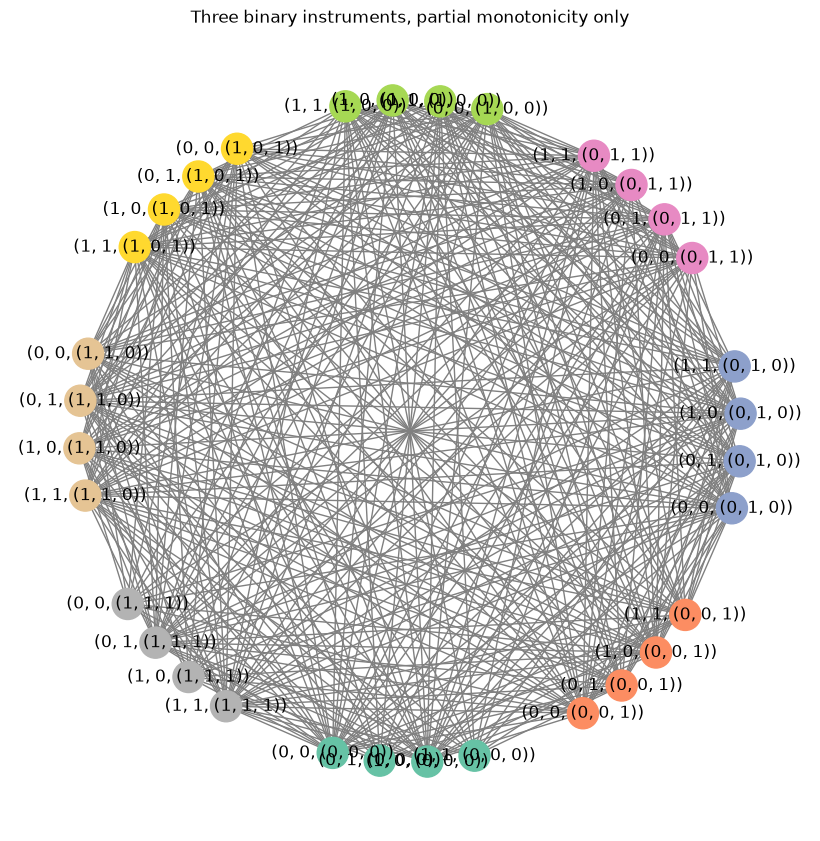

In [11]:
three = dict(y_support=(0, 1), d_support=(0, 1), z_supports=((0, 1), (0, 1), (0, 1)))
graphs_3 = {excl: PartialMonotonicityModel(**three, exclusion=excl).build_graph() for excl in (True, False)}
for excl, G in graphs_3.items():
    print(f"exclusion={excl!s:5s}: nodes = {G.number_of_nodes()}, edges = {G.number_of_edges()}")

checks = [
    ((0, 1, (1, 1, 0)), (0, 0, (1, 1, 1)), "only the third coordinate rises, D falls"),
    ((0, 0, (1, 1, 0)), (1, 1, (1, 1, 1)), "only the third coordinate rises, D rises"),
    ((0, 1, (0, 0, 1)), (0, 0, (1, 1, 0)), "third coordinate makes the vectors incomparable"),
    ((0, 1, (0, 0, 1)), (1, 1, (1, 1, 0)), "incomparable, equal D, unequal Y"),
    ((0, 1, (0, 0, 0)), (0, 0, (1, 1, 1)), "(0,0,0) <= (1,1,1), D falls"),
]
print()
print(f"{'pair':50s} {'with exclusion':16s} {'without':10s} reason")
for u, v, reason in checks:
    print(f"{str(u) + ' -- ' + str(v):50s} "
          f"{'edge' if graphs_3[True].has_edge(u, v) else 'no edge':16s} "
          f"{'edge' if graphs_3[False].has_edge(u, v) else 'no edge':10s} {reason}")

GraphAnalyzer(graphs_3[False], group_fn=lambda node: node[2]).plot_grouped_on_circle(
    title="Three binary instruments, partial monotonicity only", node_size=500, figsize=(8, 8)
)

The perfectness check of `GraphAnalyzer` enumerates vertex subsets and is not run on the 54- and 32-node graphs here. Every count and pair above is also verified in `tests/test_partial_monotonicity_model.py`, where the edge sets are compared with an enumeration of all admissible potential-response vectors (Method 2).